<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Símbolo de Python -->
            <img
                src="https://cdn3.emoji.gg/emojis/1887_python.png"
                style="margin-bottom:-5px"
                width="30px" 
                height="30px"
            >
            <!-- Título -->
            Python para Geólogos
            <!-- Versión -->
            <img 
                src="https://img.shields.io/github/release/kevinalexandr19/manual-python-geologia.svg?style=flat&label=&color=blue"
                style="margin-bottom:-2px" 
                width="40px"
            >
        </strong>
    </span>
    <br>
    <span>
        <!-- Github del proyecto -->
        <a href="https://github.com/kevinalexandr19/manual-python-geologia" target="_blank">
            <img src="https://img.shields.io/github/stars/kevinalexandr19/manual-python-geologia.svg?style=social&label=Github Repo">
        </a>
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/github/license/kevinalexandr19/manual-python-geologia.svg?color=forestgreen">
        &nbsp;&nbsp;
        <!-- Release date -->
        <img src="https://img.shields.io/github/release-date/kevinalexandr19/manual-python-geologia?color=gold">
    </span>
    <br>
    <span>
        <!-- Perfil de LinkedIn -->
        <a target="_blank" href="https://www.linkedin.com/in/kevin-alexander-gomez/">
            <img src="https://img.shields.io/badge/-Kevin Alexander Gomez-5eba00?style=social&logo=linkedin">
        </a>
        &nbsp;&nbsp;
        <!-- Perfil de Github -->
        <a target="_blank" href="https://github.com/kevinalexandr19">
            <img src="https://img.shields.io/github/followers/kevinalexandr19.svg?style=social&label=kevinalexandr19&maxAge=2592000">
        </a>
    </span>
    <br>
</div>

***

<span style="color:lightgreen; font-size:25px">**PG101 - Fundamentos de Estadística**</span>

Bienvenido al curso!!!

Vamos a revisar las bases de la <span style="color:gold">estadística</span> usando ejemplos en Python. <br>
Es necesario que tengas un conocimiento previo en programación con Python y visualización de datos con Matplotlib.

Vamos a seguir la propagación de supuestos: distribuciones de Cu y densidad → realizaciones del modelo → toneladas de Cu. Distinguiremos variabilidad simulada, error numérico Monte Carlo y evidencia sobre un yacimiento real.

<span style="color:gold; font-size:20px">**Simulación de Montecarlo** </span>

***
- [¿Qué es la simulación en Estadística?](#parte-1)
- [Simulación de Montecarlo](#parte-2)
- [Estimación del contenido de Cu en un modelo de bloques](#parte-3)
- [En conclusión...](#parte-4)

***

In [ ]:
import sys
# Preparación del entorno del navegador.
if sys.platform == 'emscripten':
    import piplite
    await piplite.install(['seaborn', 'ipywidgets', 'scipy', 'statsmodels', 'tqdm'])

<a id="parte-1"></a>

### <span style="color:lightgreen">**¿Qué es la simulación en Estadística?**</span>
***

La <span style="color:gold">simulación</span> es una técnica que se utiliza para modelar y analizar el comportamiento de sistemas complejos mediante la generación de datos aleatorios. Se basa en la creación de experimentos virtuales que imitan el proceso o fenómeno que se desea estudiar. Esta técnica es particularmente útil cuando el análisis analítico directo es complicado o imposible de realizar debido a la complejidad del sistema.

<span style="color:#43c6ac">En geología, muchos procesos son complejos y están sujetos a incertidumbres debido a la variabilidad natural de las formaciones geológicas y las limitaciones en la cantidad de datos disponibles.</span>

> Por ejemplo, la distribución de minerales en un yacimiento, la propagación de contaminantes en aguas subterráneas o la estabilidad de un talud pueden ser difíciles de modelar de manera determinista.

La simulación permite a los geólogos crear modelos que incorporen estas incertidumbres, facilitando una mejor comprensión de los posibles escenarios y ayudando en la toma de decisiones informadas. 

Al generar múltiples realizaciones de un modelo basado en diferentes suposiciones y datos aleatorios, se pueden obtener estimaciones más precisas y confiables sobre el comportamiento de los sistemas geológicos.

En una simulación estadística, se pueden generar múltiples conjuntos de datos sintéticos <span style="color:#43c6ac">basados en suposiciones sobre distribuciones de probabilidad y relaciones entre variables</span>. Estos datos sintéticos se utilizan para:

- <span style="color:lightgreen">Evaluar el comportamiento de un sistema:</span> probar cómo se comporta un sistema bajo diferentes condiciones y escenarios.
- <span style="color:lightgreen">Estimación de parámetros:</span> calcular estimaciones de parámetros desconocidos a partir de datos simulados.
- <span style="color:lightgreen">Evaluación de modelos:</span> verificar la precisión y validez de modelos estadísticos.

***

<a id="parte-2"></a>

### <span style="color:lightgreen">**Simulación de Montecarlo**</span>
***



<div style="width:100%; background-color:#031323; text-align:center; line-height:0">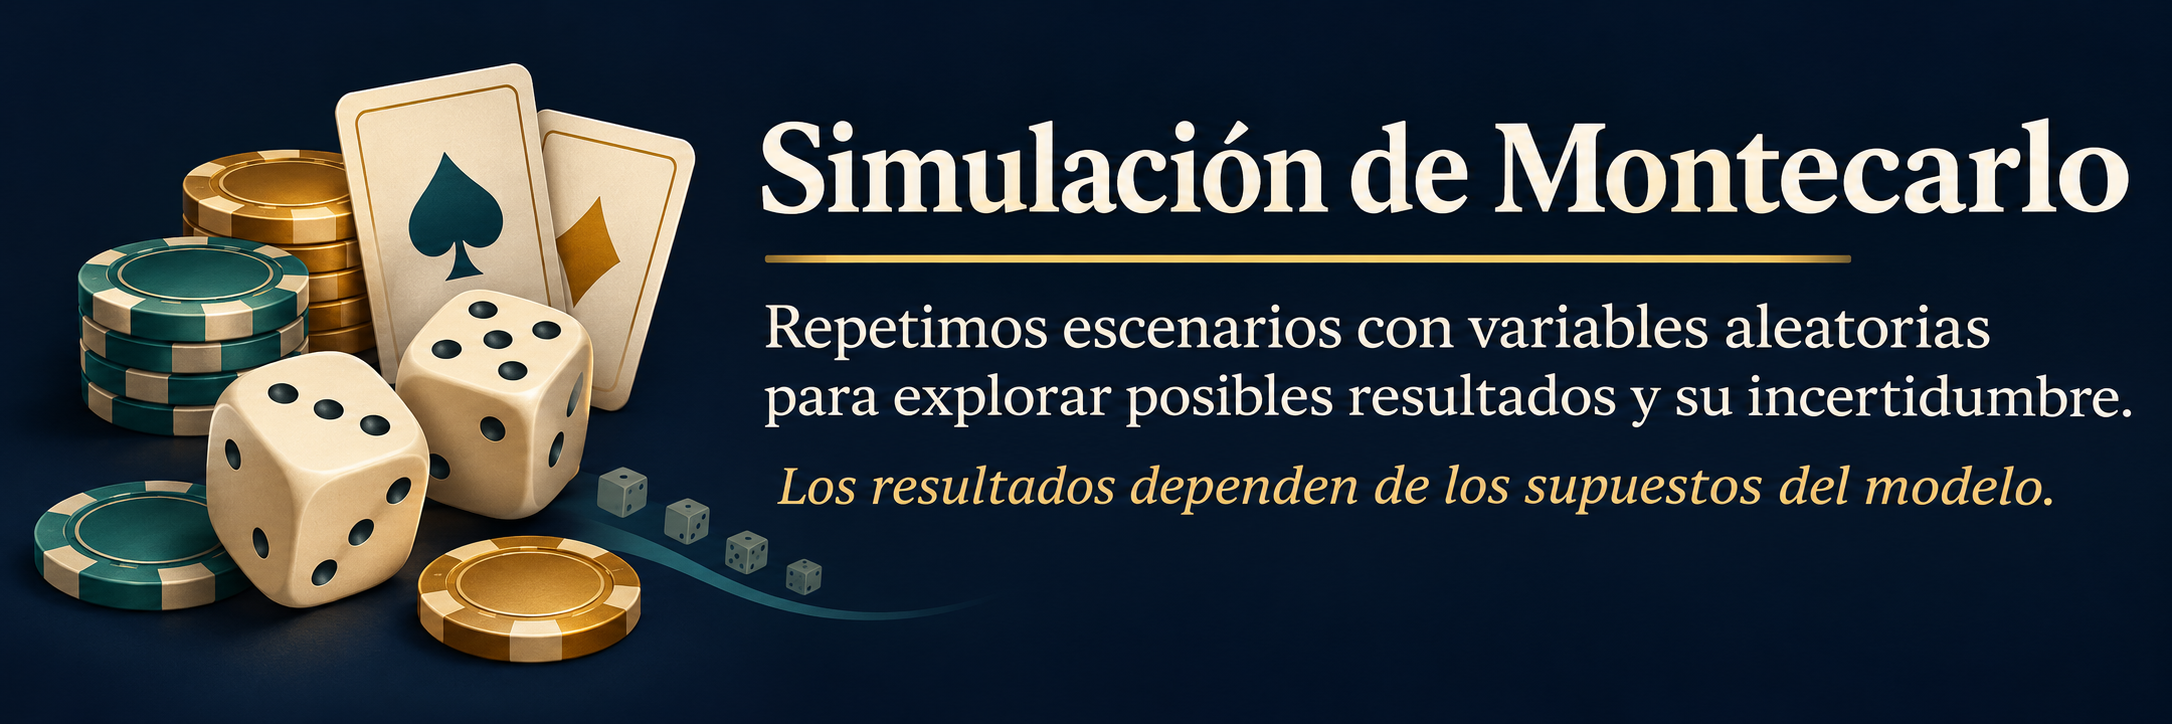</div>



<br>

La <span style="color:gold">simulación de Montecarlo</span> es una técnica de simulación estadística que utiliza métodos numéricos y <span style="color:lightgreen">la generación de números aleatorios</span> para resolver problemas que pueden ser deterministas o probabilísticos en la naturaleza. Su objetivo principal es intentar imitar el comportamiento de variables reales para analizar/predecir cómo van a evolucionar.

> El nombre "Montecarlo" proviene del famoso casino en Mónaco, reflejando el elemento de azar que es central en este método.

Los pasos para realizar una simulación de Montecarlo son los siguientes:

- <span style="color:lightgreen">Definición del problema:</span> <br>
    Especificar el problema y determinar las variables aleatorias de interés.
  
- <span style="color:lightgreen">Modelamiento de variables aleatorias:</span> <br>
    Asignar distribuciones de probabilidad apropiadas a las variables inciertas del problema y utilizar generadores de números aleatorios (RNG) para obtener valores de las distribuciones especificadas.

- <span style="color:lightgreen">Simulación de experimentos:</span> <br>
    Realizar un gran número de experimentos virtuales, utilizando los números aleatorios generados.

- <span style="color:lightgreen">Análisis de resultados:</span> <br>
    Analizar los resultados de los experimentos para estimar parámetros, evaluar riesgos, y tomar decisiones informadas.

En este notebook, abordaremos un ejemplo práctico para entender el concepto de simulación.

Vamos a centrarnos en <span style="color:#43c6ac">el proceso de estimación del contenido de cobre (Cu) en un modelo de bloques utilizando la simulación de Montecarlo</span>. Empezaremos cargando y preparando los datos, luego asignaremos distribuciones de probabilidad adecuadas a las variables inciertas, y generaremos números aleatorios para nuestras simulaciones.

Al realizar múltiples realizaciones del modelo, podremos incorporar la variabilidad y las incertidumbres inherentes a las propiedades geológicas del yacimiento, proporcionando así una estimación más robusta y confiable de la cantidad total de cobre.

***

### <span style="color:gold">**Del supuesto al resultado**</span>

Lee el diagrama de izquierda a derecha. El número de simulaciones controla la estabilidad numérica, pero no demuestra que los supuestos sean correctos.

In [ ]:
import matplotlib.pyplot as plt
fig, eje = plt.subplots(figsize=(10,2.5))
etapas = ['Supuestos\nCu (%) y densidad', 'Una realización\npor bloque', 'Suma del metal\ncontenido (t)', 'Repetir y resumir\nN totales']
for i, texto in enumerate(etapas):
    x = .12 + i*.25
    eje.text(x,.5,texto,ha='center',va='center',transform=eje.transAxes,
             bbox=dict(boxstyle='round,pad=.6',fc='#e5f2fa',ec='#0072B2'),fontsize=10)
    if i < 3:eje.annotate('',xy=(x+.16,.5),xytext=(x+.09,.5),xycoords='axes fraction',arrowprops=dict(arrowstyle='->',color='#555555'))
eje.set_axis_off()
eje.set_title('Monte Carlo propaga los supuestos; no los valida')
fig.tight_layout()
plt.show()

<a id="parte-3"></a>

### <span style="color:lightgreen">**Estimación del contenido de Cu en un modelo de bloques** </span>
***

Empezaremos cargando un archivo CSV que contiene información sobre las diferentes litologías presentes en un modelo de bloques.

Usaremos todos los bloques del CSV para los cálculos. Los cortes nos ayudarán a reconocer la geometría y la distribución de litologías antes de simular sus propiedades.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from tqdm.notebook import tqdm
import sys


In [ ]:
# Modelo de bloques
modelo = pd.read_csv("files/blocks.csv")

# Mostramos filas aleatorias del modelo de bloques
modelo.sample(10, random_state=42)

In [ ]:
# Estadísticas de X, Y, Z
modelo.describe().T

In [ ]:
# Lista de litologías
for lito in modelo["LITO"].unique():
    print(lito)

El modelo contiene las siguientes columnas:

- `X`, `Y`, `Z`: coordenadas XYZ de los centroides de cada bloque, el lado de cada bloque es de 25 metros.
- `LITO`: columna categórica con la clasificación litológica de cada bloque.

In [ ]:
# Definir colores para cada litología
lito_color = {"BASAMENTO": "maroon",
              "PREMINERAL": "red",
              "PORFIDO": "blue",
              "INTRAMINERAL": "green",
              "DIQUES": "yellow",
              "CUATERNARIO": "gray"
             }

### <span style="color:gold">**¿Cómo podemos mirar dentro del modelo?**</span>

Vamos a representar el modelo mediante tres cortes perpendiculares usando Matplotlib. Cada cuadrado corresponde a la cara de un bloque de **25 m × 25 m** y su color identifica la litología.

- **Planta XY:** fijamos Z y observamos el modelo desde arriba.
- **Sección XZ:** fijamos Y y observamos cómo cambia la geología con Z.
- **Sección YZ:** fijamos X y observamos el modelo desde otra dirección.

Seleccionaremos un nivel existente cercano a la mediana de cada coordenada. Las líneas discontinuas indican dónde se cruzan los otros dos cortes. Z se muestra como coordenada creciente hacia arriba; no la convertimos en profundidad.

> Las zonas grises indican posiciones sin bloques en el CSV. No les asignamos una litología ni un valor de Cu. Los cortes muestran solo una parte del modelo; la estimación usará **todos los bloques**.

Antes de ejecutar el código, identifica la lógica: **fijar una coordenada → filtrar filas → ordenar los valores en una malla → asignar colores**. En la función, `pivot` organiza las filas y columnas del corte; `reindex` conserva los huecos como valores ausentes.


In [ ]:
from matplotlib.colors import ListedColormap, BoundaryNorm, LogNorm
from matplotlib.patches import Patch

# Elegir niveles que realmente existen en el CSV.
niveles_corte = {}
for coordenada in ["X", "Y", "Z"]:
    niveles = np.sort(modelo[coordenada].unique())
    niveles_corte[coordenada] = niveles[np.argmin(abs(niveles - modelo[coordenada].median()))]

# Coordenada fija, eje horizontal, eje vertical y nombre del corte.
cortes = [("Z", "X", "Y", "Planta XY"),
          ("Y", "X", "Z", "Sección XZ"),
          ("X", "Y", "Z", "Sección YZ")]

def dibujar_corte(ax, datos, fija, horizontal, vertical, nombre, campo, cmap, norm):
    nivel = niveles_corte[fija]
    corte = datos[datos[fija] == nivel] # Filtrar una capa de bloques.
    x = np.sort(modelo[horizontal].unique())
    y = np.sort(modelo[vertical].unique())
    malla = corte.pivot(index=vertical, columns=horizontal, values=campo)
    malla = malla.reindex(index=y, columns=x) # Los huecos quedan como NaN.

    # El CSV contiene centroides: los bordes están a 12.5 m de cada centro.
    bordes_x = np.append(x - 12.5, x[-1] + 12.5)
    bordes_y = np.append(y - 12.5, y[-1] + 12.5)
    imagen = ax.pcolormesh(bordes_x, bordes_y, malla.to_numpy(),
                          cmap=cmap, norm=norm, shading="flat")
    ax.axvline(niveles_corte[horizontal], color="k", ls="--", lw=0.8)
    ax.axhline(niveles_corte[vertical], color="k", ls="--", lw=0.8)
    ax.set(xlabel=f"{horizontal} (m)", ylabel=f"{vertical} (m)",
           title=f"{nombre}: {fija} = {nivel:g} m")
    ax.set_aspect("equal") # Un metro ocupa el mismo espacio en ambos ejes.
    ax.set_facecolor("#eeeeee")
    return imagen

# Los números son códigos de categorías; no representan cantidades de roca.
codigos_lito = {lito: i for i, lito in enumerate(lito_color)}
vista_lito = modelo.assign(codigo_lito=modelo["LITO"].map(codigos_lito))
cmap_lito = ListedColormap(list(lito_color.values()))
norm_lito = BoundaryNorm(np.arange(len(lito_color) + 1) - 0.5, len(lito_color))

fig_cortes, axs = plt.subplots(1, 3, figsize=(13, 5.5))
for ax, (fija, horizontal, vertical, nombre) in zip(axs, cortes):
    dibujar_corte(ax, vista_lito, fija, horizontal, vertical, nombre,
                  "codigo_lito", cmap_lito, norm_lito)
leyenda = [Patch(facecolor=color, label=lito) for lito, color in lito_color.items()]
fig_cortes.legend(handles=leyenda, loc="lower center", ncol=3, frameon=False)
fig_cortes.suptitle("Modelo de bloques — litologías en tres cortes perpendiculares")
fig_cortes.tight_layout(rect=[0, 0.13, 0.99, 0.94])
plt.show()


Lee los tres paneles como partes del **mismo modelo 3D**. El color de una litología se mantiene en todos los cortes. Cada panel muestra una capa de 25 m de espesor, sin superponer los bloques que están delante o detrás.

Para entender el código, prueba lo siguiente:

1. Antes de cambiar un nivel en `niveles_corte`, predice qué panel cambiará y qué líneas se moverán en los otros dos.
2. Usa otro valor que aparezca en `modelo["Z"].unique()` y vuelve a ejecutar la figura, sin ejecutar de nuevo la celda que elige los niveles iniciales. ¿Qué litologías aparecen o desaparecen en la planta?
3. Explica por qué cambiar el corte modifica la figura, pero no el número de bloques que usaremos en la simulación.

La geometría y la litología permanecerán fijas en este ejemplo. Lo que vamos a simular es la **ley de Cu y la densidad de cada bloque**, según su litología.


***
<span style="color:gold">**Modelamiento de variables aleatorias** </span>

El modelamiento de variables aleatorias es un paso esencial en la simulación de Montecarlo, ya que permite capturar y representar la variabilidad y la incertidumbre inherentes a las propiedades geológicas de un yacimiento. Este proceso implica asignar distribuciones de probabilidad adecuadas a las variables inciertas del modelo, como la concentración de cobre (Cu) y la densidad de diferentes litologías.

Para cada litología presente en el modelo de bloques, vamos a definir distribuciones de probabilidad basadas en datos geológicos y suposiciones generales sobre las características de las rocas. Estas distribuciones reflejan la variabilidad natural en las concentraciones de Cu y las densidades de cada litología. Por ejemplo, las rocas de pórfido suelen tener concentraciones más altas de Cu, mientras que las rocas de basamento y cuaternario tienden a tener concentraciones más bajas.

> Asignar distribuciones de probabilidad implica <span style="color:#43c6ac">seleccionar una distribución estadística</span> (como la normal, log-normal, etc.) que describa adecuadamente la variabilidad observada en los datos. Una vez seleccionada la distribución, se definen los parámetros correspondientes, como la media y la desviación estándar, para cada litología. Estos parámetros se pueden derivar de datos históricos, estudios geológicos y análisis de muestras.

Una vez que las distribuciones de probabilidad están definidas, utilizaremos generadores de números aleatorios para obtener valores de estas distribuciones. Estos valores representan realizaciones posibles de las propiedades geológicas bajo estudio. Por ejemplo, para cada litología, generaremos 10,000 valores aleatorios de Cu y densidad, que luego se utilizarán en la simulación de experimentos.

Los parámetros por litología son supuestos didácticos, no ajustes validados con ensayes. En `rng.lognormal`, mean y sigma pertenecen al logaritmo natural de Cu. Las normales de densidad tienen soporte no físico negativo, aunque con estos parámetros esa probabilidad es muy pequeña.

In [ ]:
# Generador de números aleatorios
rng = np.random.default_rng(42)

# Número de valores aleatorios en cada distribución
n = 2000

# Diccionario para almacenar las distribuciones de cada litología
distribuciones = {}

`BASAMENTO`: <br>
El basamento representa las rocas más antiguas y generalmente más profundas en el yacimiento. Estas rocas suelen tener bajas concentraciones de Cu debido a su antigüedad y la falta de procesos mineralizantes recientes. Asignaremos una distribución lognormal con una media baja para Cu y una densidad típica de rocas ígneas profundas.

In [ ]:
# Modelamiento de variables aleatorias
distribuciones["BASAMENTO"] = {
    "Cu": lambda size=None: rng.lognormal(mean=-4.5, sigma=0.06, size=size),
    "Densidad": lambda size=None: rng.normal(loc=2.85, scale=0.04, size=size)
}

In [ ]:
# Datos de entrada para el gráfico
litologia = "BASAMENTO"
lito_rng = distribuciones[litologia] # RNG de Cu y densidad
cu = [1e4 * lito_rng["Cu"]() for _ in range(n)] # Transformado de % a ppm
densidad = [lito_rng["Densidad"]() for _ in range(n)]

# Figura principal
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

# Figura 1. Distribución de Cu
axs[0].hist(cu, bins=100, edgecolor="k", linewidth=0.5, color="#B87333")

# Figura 2. Distribución de densidad
axs[1].hist(densidad, bins=100, edgecolor="k", linewidth=0.5)

# Detalles
fig.suptitle(f"{litologia} ({n:,} simulaciones)")
axs[0].set_title("Cu (ppm)")
axs[0].set_ylabel("Frecuencia")
axs[1].set_title("Densidad (g/cm³)")
for ax in axs:
    ax.grid(lw=0.5, alpha=0.5, c="k")
    ax.set_axisbelow(True)

# Mostrar la figura
plt.tight_layout()

`PREMINERAL`: <br>
Estas son las rocas que existían antes del evento de mineralización principal. Aunque pueden haber sido afectadas por procesos hidrotermales, su contenido de Cu generalmente será menor comparado con las litologías sin-mineral o intramineral.

In [ ]:
# Modelamiento de variables aleatorias
distribuciones["PREMINERAL"] = {
    "Cu": lambda size=None: rng.lognormal(mean=-1.5, sigma=0.2, size=size),
    "Densidad": lambda size=None: rng.normal(loc=2.7, scale=0.03, size=size)
}

In [ ]:
# Datos de entrada para el gráfico
litologia = "PREMINERAL"
lito_rng = distribuciones[litologia] # RNG de Cu y densidad
cu = [1e4 * lito_rng["Cu"]() for _ in range(n)] # Transformado de % a ppm
densidad = [lito_rng["Densidad"]() for _ in range(n)]

# Figura principal
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

# Figura 1. Distribución de Cu
axs[0].hist(cu, bins=100, edgecolor="k", linewidth=0.5, color="#B87333")

# Figura 2. Distribución de densidad
axs[1].hist(densidad, bins=100, edgecolor="k", linewidth=0.5)

# Detalles
fig.suptitle(f"{litologia} ({n:,} simulaciones)")
axs[0].set_title("Cu (ppm)")
axs[0].set_ylabel("Frecuencia")
axs[1].set_title("Densidad (g/cm³)")
for ax in axs:
    ax.grid(lw=0.5, alpha=0.5, c="k")
    ax.set_axisbelow(True)

# Mostrar la figura
plt.tight_layout()

`PORFIDO`: <br>
El pórfido es la litología clave en muchos yacimientos de cobre tipo pórfido. Estas rocas están altamente mineralizadas y presentan concentraciones significativas de Cu. Asignaremos una distribución lognormal con una media alta para Cu y una densidad apropiada.

In [ ]:
# Modelamiento de variables aleatorias
distribuciones["PORFIDO"] = {
    "Cu": lambda size=None: rng.lognormal(mean=0.25, sigma=0.4, size=size),
    "Densidad": lambda size=None: rng.normal(loc=2.65, scale=0.03, size=size)
}

In [ ]:
# Datos de entrada para el gráfico
litologia = "PORFIDO"
lito_rng = distribuciones[litologia] # RNG de Cu y densidad
cu = [lito_rng["Cu"]() for _ in range(n)]
densidad = [lito_rng["Densidad"]() for _ in range(n)]

# Figura principal
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

# Figura 1. Distribución de Cu
axs[0].hist(cu, bins=100, edgecolor="k", linewidth=0.5, color="#B87333")

# Figura 2. Distribución de densidad
axs[1].hist(densidad, bins=100, edgecolor="k", linewidth=0.5)

# Detalles
fig.suptitle(f"{litologia} ({n:,} simulaciones)")
axs[0].set_title("Cu (%)")
axs[0].set_ylabel("Frecuencia")
axs[1].set_title("Densidad (g/cm³)")
for ax in axs:
    ax.grid(lw=0.5, alpha=0.5, c="k")
    ax.set_axisbelow(True)

# Mostrar la figura
plt.tight_layout()

`INTRAMINERAL`: <br>
Las rocas intraminerales se formaron durante el evento de mineralización y están altamente alteradas y mineralizadas. Estas litologías tendrán concentraciones de Cu comparables o incluso superiores a las del pórfido debido a su asociación directa con los fluidos mineralizantes.

In [ ]:
# Modelamiento de variables aleatorias
distribuciones["INTRAMINERAL"] = {
    "Cu": lambda size=None: rng.lognormal(mean=0.7, sigma=0.5, size=size),
    "Densidad": lambda size=None: rng.normal(loc=2.63, scale=0.03, size=size)
}

In [ ]:
# Datos de entrada para el gráfico
litologia = "INTRAMINERAL"
lito_rng = distribuciones[litologia] # RNG de Cu y densidad
cu = [lito_rng["Cu"]() for _ in range(n)]
densidad = [lito_rng["Densidad"]() for _ in range(n)]

# Figura principal
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

# Figura 1. Distribución de Cu
axs[0].hist(cu, bins=100, edgecolor="k", linewidth=0.5, color="#B87333")

# Figura 2. Distribución de densidad
axs[1].hist(densidad, bins=100, edgecolor="k", linewidth=0.5)

# Detalles
fig.suptitle(f"{litologia} ({n:,} simulaciones)")
axs[0].set_title("Cu (%)")
axs[0].set_ylabel("Frecuencia")
axs[1].set_title("Densidad (g/cm³)")
for ax in axs:
    ax.grid(lw=0.5, alpha=0.5, c="k")
    ax.set_axisbelow(True)

# Mostrar la figura
plt.tight_layout()

`DIQUES`: <br>
Los diques son intrusiones ígneas que cortan a través de las rocas preexistentes. Dependiendo de su composición y el momento de su formación, los diques pueden contener valores significativos de Cu y una densidad similar a la del basamento. Modelaremos estas variaciones con distribuciones adecuadas.

In [ ]:
# Modelamiento de variables aleatorias
distribuciones["DIQUES"] = {
    "Cu": lambda size=None: rng.lognormal(mean=-0.5, sigma=0.25, size=size),
    "Densidad": lambda size=None: rng.normal(loc=2.75, scale=0.03, size=size)
}

In [ ]:
# Datos de entrada para el gráfico
litologia = "DIQUES"
lito_rng = distribuciones[litologia] # RNG de Cu y densidad
cu = [lito_rng["Cu"]() for _ in range(n)]
densidad = [lito_rng["Densidad"]() for _ in range(n)]

# Figura principal
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

# Figura 1. Distribución de Cu
axs[0].hist(cu, bins=100, edgecolor="k", linewidth=0.5, color="#B87333")

# Figura 2. Distribución de densidad
axs[1].hist(densidad, bins=100, edgecolor="k", linewidth=0.5)

# Detalles
fig.suptitle(f"{litologia} ({n:,} simulaciones)")
axs[0].set_title("Cu (%)")
axs[0].set_ylabel("Frecuencia")
axs[1].set_title("Densidad (g/cm³)")
for ax in axs:
    ax.grid(lw=0.5, alpha=0.5, c="k")
    ax.set_axisbelow(True)

# Mostrar la figura
plt.tight_layout()

`CUATERNARIO`: <br>
Esta litología representa los depósitos más recientes y superficiales, generalmente compuestos de sedimentos no consolidados. Las concentraciones de Cu en estos depósitos suelen ser bajas debido a su naturaleza superficial y la falta de procesos mineralizantes intensivos. También suelen tener una densidad significativamente menor que las rocas más antiguas y consolidadas.

In [ ]:
# Modelamiento de variables aleatorias
distribuciones["CUATERNARIO"] = {
    "Cu": lambda size=None: rng.lognormal(mean=-4, sigma=0.25, size=size),
    "Densidad": lambda size=None: rng.normal(loc=2.4, scale=0.05, size=size)
}

In [ ]:
# Datos de entrada
litologia = "CUATERNARIO"
lito_rng = distribuciones[litologia] # RNG de Cu y densidad
cu = [1e4 * lito_rng["Cu"]() for _ in range(n)] # Transformado de % a ppm
densidad = [lito_rng["Densidad"]() for _ in range(n)]

# Figura principal
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

# Figura 1. Distribución de Cu
axs[0].hist(cu, bins=100, edgecolor="k", linewidth=0.5, color="#B87333")

# Figura 2. Distribución de densidad
axs[1].hist(densidad, bins=100, edgecolor="k", linewidth=0.5)

# Detalles
fig.suptitle(f"{litologia} ({n:,} simulaciones)")
axs[0].set_title("Cu (ppm)")
axs[0].set_ylabel("Frecuencia")
axs[1].set_title("Densidad (g/cm³)")
for ax in axs:
    ax.grid(lw=0.5, alpha=0.5, c="k")
    ax.set_axisbelow(True)

# Mostrar la figura
plt.tight_layout()

Ahora que hemos modelado las litologías y asignado distribuciones de probabilidad a las variables inciertas, procederemos a visualizar un gráfico resumen. 

> Este gráfico nos permitirá comparar y analizar de manera clara y concisa los valores de Cu y densidad para todas las litologías en un solo lugar, facilitando así la interpretación de los resultados y la identificación de patrones y tendencias en los datos.

In [ ]:
n = 2000 # Número de simulaciones

# Figura principal
fig, axs = plt.subplots(2, 1, figsize=(9, 6))

# Iterar por cada litología
for lito in distribuciones.keys():
    lito_rng = distribuciones[lito] # RNG de Cu y densidad
    # Figura 1. Histograma de log Cu (%)
    sns.kdeplot(np.log10([lito_rng["Cu"]() for _ in range(n)]), alpha=0.5,
                ax=axs[0], fill=True, color=lito_color[lito], label=lito)
    # Figura 2. Histograma de densidad (g/cm3)
    sns.kdeplot([lito_rng["Densidad"]() for _ in range(n)], alpha=0.5,
                ax=axs[1], fill=True, color=lito_color[lito], label=lito)

# Detalles adicionales
fig.suptitle(f"RESUMEN TOTAL ({n:,} simulaciones)")
axs[0].set_title("log10 de Cu (%)")
axs[1].set_title("Densidad (g/cm³)")
for ax in axs:
    ax.grid(lw=0.5, alpha=0.25, c="k", ls="--")
    ax.set_axisbelow(True)
    ax.set_ylabel("Densidad en el eje representado")
    ax.legend(title="Litología", bbox_to_anchor=(1.3, 0.8))
    
# Mostrar la figura
plt.tight_layout()

Observamos altos valores de Cu en las litologías de `PREMINERAL`, `PORFIDO`, `DIQUES` e `INTRAMINERAL`, en contraste con los bajos valores de Cu en `BASAMENTO` y `CUATERNARIO`. En cuanto a la densidad, el `BASAMENTO` presenta los valores más altos, seguido por las demás litologías, con excepción del `CUATERNARIO`, que tiene una densidad baja.

***
<span style="color:gold">**Simulación de experimentos** </span>

Durante la simulación de experimentos, se generan múltiples realizaciones del modelo para evaluar la variabilidad y las incertidumbres inherentes. En este contexto, generaremos un gran número de experimentos virtuales utilizando los valores aleatorios obtenidos de las distribuciones de probabilidad asignadas a nuestras variables inciertas.

<span style="color:#43c6ac">Al generar un gran número de simulaciones, podemos obtener una visión estadística de cómo varían estos valores y qué tan confiables son nuestras estimaciones.</span>

El objetivo del modelo es calcular la cantidad total de cobre en el modelo de bloques. Esto se logra evaluando la ley de Cu, que es la concentración de cobre en cada bloque, y combinándola con la densidad de la roca y el volumen del bloque. La cantidad de cobre en cada bloque se calcula utilizando la siguiente fórmula:



$$
\Large \text{Cu Total} = \text{Ley de Cu} \times \text{Densidad} \times \text{Volumen}
$$

<br>

Este cálculo se realiza para cada bloque del modelo de bloques en cada una de las simulaciones. Al sumar la cantidad de cobre de todos los bloques, obtenemos una estimación del contenido total de cobre en el yacimiento para cada realización de la simulación.

El ejemplo supone independencia entre bloques, entre Cu y densidad y entre realizaciones. La correlación espacial y la dependencia ley-densidad pueden cambiar mucho la incertidumbre del total; más simulaciones no corrigen supuestos inadecuados.

In [ ]:
from tqdm.notebook import tqdm
from scipy.stats import anderson # Prueba de Anderson-Darling
from statsmodels.stats.api import lilliefors # Prueba de Lilliefors (Kolmogorov-Smirnov adaptada para parámetros estimados)

# Función que simula un valor aleatorio de Cu
def simulate_Cu(litologia):
    lito_rng = distribuciones[litologia]
    return lito_rng["Cu"]()
    
# Función que simula un valor aleatorio de Densidad
def simulate_Density(litologia):
    lito_rng = distribuciones[litologia]
    return lito_rng["Densidad"]()

# Número de simulaciones
N = 200

# Arrays vacíos para almacenar las simulaciones de Cu y Densidad
simulaciones_Cu = np.zeros((len(modelo), 1))
simulaciones_Densidad = np.zeros((len(modelo), 1))

# Evitar hilos auxiliares en Pyodide.
if sys.platform == 'emscripten':
    tqdm.monitor_interval = 0

# Solo se retienen los totales y la primera realización completa.
simulaciones_Cu_total = np.zeros(N)
mascaras_lito = {lito: (modelo['LITO'].to_numpy()==lito) for lito in distribuciones}

La simulación puede ser un proceso que consume tiempo debido a la necesidad de realizar una gran cantidad de simulaciones para obtener resultados precisos, siguiendo el principio de la ley de los grandes números. 

Para gestionar y monitorear el progreso del proceso de generación de datos simulados, utilizaremos la librería `tqdm`, que nos proporcionará una barra de progreso. Esto nos permitirá visualizar el avance de la simulación de manera más efectiva.

Con 119443 bloques, guardar dos matrices de 1000 realizaciones usaría aproximadamente 1.9 GB solo para sus valores float64. Procesaremos una realización por vez: conservamos la primera para visualizarla y los 200 totales para resumirlos. Puedes aumentar N después de revisar tiempo y estabilidad.

In [ ]:
# Una realización por vez: mismo modelo completo, memoria acotada.
volumen = 25 ** 3
for i in tqdm(range(N)):
    cu_actual = np.empty(len(modelo))
    densidad_actual = np.empty(len(modelo))
    for lito, mascara in mascaras_lito.items():
        cantidad = int(mascara.sum())
        cu_actual[mascara] = distribuciones[lito]['Cu'](cantidad)
        densidad_actual[mascara] = distribuciones[lito]['Densidad'](cantidad)
    simulaciones_Cu_total[i] = np.sum(cu_actual / 100 * densidad_actual * volumen)
    if i == 0:
        simulaciones_Cu[:,0] = cu_actual
        simulaciones_Densidad[:,0] = densidad_actual

### <span style="color:gold">**De la litología al Cu simulado**</span>

Ahora vamos a mirar los mismos cortes, coloreando cada bloque con la **ley de Cu de la primera realización**. La función es la misma: cambiamos el campo que vamos a representar y la escala de colores.

La barra de color es común a los tres paneles y usa una escala logarítmica: distancias iguales en la barra representan factores multiplicativos. Los valores siguen expresados en **Cu (%)**. Usamos esta escala porque las leyes de Cu de las distintas litologías abarcan varios órdenes de magnitud.

> Estos valores fueron generados por nuestras distribuciones; no son ensayes medidos. Las variaciones entre bloques vecinos reflejan el supuesto de independencia del ejemplo, no una continuidad espacial validada.


In [ ]:
# Mantener el orden de las filas: cada valor simulado pertenece a un bloque.
vista_cu = modelo.assign(Cu=simulaciones_Cu[:, 0])
norm_cu = LogNorm(vmin=vista_cu["Cu"].min(), vmax=vista_cu["Cu"].max())

fig_cu_cortes, axs = plt.subplots(1, 3, figsize=(13, 5), layout="constrained")
for ax, (fija, horizontal, vertical, nombre) in zip(axs, cortes):
    imagen = dibujar_corte(ax, vista_cu, fija, horizontal, vertical, nombre,
                          "Cu", "viridis", norm_cu)
fig_cu_cortes.colorbar(imagen, ax=axs, label="Cu (%) — escala logarítmica", shrink=0.7)
fig_cu_cortes.suptitle("Primera realización — misma geometría, propiedades simuladas")
plt.show()


Antes de continuar, compara estos cortes con los de litología. ¿Dónde esperarías leyes más altas según las distribuciones que definimos? ¿Todos los bloques de una misma litología tienen exactamente el mismo valor?

Para estimar el metal contenido, convertimos la ley de cada bloque de porcentaje a fracción, multiplicamos por su densidad y por **25³ m³**, y sumamos las contribuciones de **todos los bloques del CSV**. Los bloques visibles en los cortes también están incluidos en esa suma; no sumamos los tres paneles, porque comparten bloques en sus intersecciones.

En cada realización se generan nuevos valores de Cu y densidad. La posición y la litología de los bloques se conservan. Así obtenemos un nuevo total de Cu para comparar con los demás totales simulados.


Ahora, vamos a graficar la distribución de una de las simulaciones de Cu y Densidad para visualizar los resultados:

In [ ]:
# Figura principal
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Figura 1. Histograma de Cu (%)
sns.kdeplot(ax=axs[0], x=np.log10(simulaciones_Cu[:, 0]), alpha=0.5, fill=True)

# Figura 2. Histograma de Densidad (g/cm3)
sns.kdeplot(ax=axs[1], x=simulaciones_Densidad[:, 0], alpha=0.5, fill=True)

# Detalles adicionales
fig.suptitle(f"Modelo de bloques - Simulación 1/{N}")
axs[0].set_title("log10 de Cu (%)")
axs[1].set_title("Densidad (g/cm³)")
for ax in axs:
    ax.grid(lw=0.5, alpha=0.5, c="k", ls="--")
    ax.set_axisbelow(True)

# Mostrar la figura
plt.tight_layout()

Ahora, vamos a calcular la cantidad total de Cu en el modelo de bloques:
> Las unidades de densidad en g/cm³ son equivalentes a T/m³. <br>
> Cada bloque tiene una dimensión de 25 m x 25 m x 25 m.

Verifica las unidades: Cu(%) / 100 × densidad(t/m³) × volumen(m³) = toneladas de Cu. Se calcula metal contenido, no reservas recuperables ni metal vendible.

In [ ]:
volumen = 25 * 25 * 25 # m³
# El total de cada realización ya se calculó al procesarla.
primer_total = np.sum(simulaciones_Cu[:,0] / 100 * simulaciones_Densidad[:,0] * volumen)
print(f'Cu contenido en la primera realización: {primer_total:,.1f} toneladas')
print(f'Totales retenidos: {len(simulaciones_Cu_total)}')

***
<span style="color:gold">**Análisis de resultados** </span>

Al generar múltiples realizaciones, <span style="color:#43c6ac">podemos analizar la distribución de las estimaciones del contenido total de cobre y evaluar la incertidumbre asociada a estas estimaciones</span>. Esto nos permite construir intervalos de confianza y evaluar el riesgo asociado a diferentes escenarios de extracción. La capacidad de realizar simulaciones repetidas y analizar los resultados proporciona una comprensión más robusta y confiable de la cantidad de cobre disponible, facilitando decisiones informadas sobre la viabilidad económica y la planificación de la extracción del yacimiento.

Empezaremos verificando la normalidad de la distribución de Cu total en el modelo usando las pruebas de Lilliefors y Anderson-Darling:

> La <span style="color:gold">prueba de Lilliefors</span> es una versión modificada de la prueba de Kolmogorov-Smirnov (K-S) que se utiliza para evaluar la normalidad de los datos. La diferencia clave es que la prueba de Lilliefors es adecuada para datos en los que los parámetros de la distribución (media y desviación estándar) se han estimado a partir de la muestra, mientras que la prueba de K-S tradicional asume que estos parámetros son conocidos y no se basan en la muestra. <br>
> <span style="color:#43c6ac">El propósito de la prueba de Lilliefors es verificar si una muestra de datos sigue una distribución normal cuando los parámetros de la distribución se estiman a partir de la muestra.</span>

> La <span style="color:gold">prueba de Anderson-Darling</span> es una prueba de bondad de ajuste que evalúa si una muestra de datos proviene de una distribución específica. Es una versión mejorada de la prueba de Kolmogorov-Smirnov, ya que da más peso a las colas de la distribución, lo que la hace más sensible a las desviaciones en estas áreas. <br>
> <span style="color:#43c6ac">El propósito de la prueba de Anderson-Darling es determinar si una muestra sigue una distribución específica, comúnmente una distribución normal.</span> Sin embargo, puede adaptarse para otras distribuciones como la exponencial, log-normal, entre otras.

Un p-valor no es la probabilidad de que el modelo sea normal. No rechazar normalidad no demuestra que lo sea ni valida las distribuciones de entrada.

In [ ]:
# Prueba de Lilliefors
stat, p_value = lilliefors(simulaciones_Cu_total)
print(f"Estadístico de Lilliefors: {stat:.4f}, p-valor: {p_value:.4f}")

# Evaluar si los datos son normales
if p_value > 0.05:
    print("Prueba de Lilliefors: Los datos parecen seguir una distribución normal (no se rechaza la hipótesis nula).")
else:
    print("Prueba de Lilliefors: Se rechaza el modelo normal al nivel del 5%.")

In [ ]:
# Prueba de Anderson-Darling
result = anderson(simulaciones_Cu_total, dist="norm")

# Evaluar si los datos son normales
print(f"Estadístico de Anderson-Darling: {result.statistic:.4f}")
if result.statistic < result.critical_values[2]:  # Usar el nivel de significancia del 5%
    print("Prueba de Anderson-Darling: Los datos parecen seguir una distribución normal (no se rechaza la hipótesis nula).")
else:
    print("Prueba de Anderson-Darling: Se rechaza el modelo normal al nivel del 5%.")

Sin afirmar que la normalidad haya sido demostrada, usaremos un histograma para visualizar la distribución de valores de Cu total en el modelo de bloques. Esta herramienta nos permitirá evaluar visualmente cómo se distribuyen las concentraciones de Cu en todo el yacimiento y analizar la variabilidad de los valores simulados. 

In [ ]:
# Figura principal
fig, ax = plt.subplots(figsize=(8, 6))

# Histograma
ax.hist(simulaciones_Cu_total / 1e6, bins=50, edgecolor="k")

# Detalles adicionales
ax.set_title("Modelo de bloques - Contenido total de Cu (millones de toneladas)")
ax.set_xlabel('Cu contenido (millones de toneladas)')
ax.set_ylabel('Número de realizaciones')
ax.grid(lw=0.5, alpha=0.5, c="k")
ax.set_axisbelow(True)

# Mostrar la figura
plt.show()

Observamos la distribución de los totales bajo el modelo supuesto. El teorema del límite central puede motivar una aproximación normal para sumas de muchas contribuciones bajo condiciones apropiadas (por ejemplo, independencia y varianzas finitas, sin dominio de una sola contribución).

El número N de realizaciones mejora la descripción numérica de esa distribución; no hace normal el total por sí mismo. Cada realización ya suma los bloques del modelo. Una campana o una prueba de normalidad no validan el modelo geológico.

Los **intervalos centrales de simulación** resumen la variabilidad de los resultados bajo los supuestos de entrada. Aquí usaremos los percentiles 2.5 y 97.5 de los totales simulados, sin exigir normalidad.

Esto es distinto del **error estándar Monte Carlo de la media**, s/√N, que mide cuánto fluctúa la estimación numérica de la media con un número finito de realizaciones. No convierte las simulaciones en nuevas observaciones de campo ni mide toda la incertidumbre geológica.

In [ ]:
media = simulaciones_Cu_total.mean()
std = simulaciones_Cu_total.std(ddof=1)
limite_inferior, limite_superior = np.quantile(simulaciones_Cu_total, [.025,.975])
error_montecarlo = std / np.sqrt(N)
print('Intervalo central empírico del 95% de los totales simulados:')
print(f'[{limite_inferior:,.1f} - {limite_superior:,.1f}] toneladas')
print(f'Error estándar Monte Carlo de la media: {error_montecarlo:,.1f} toneladas')

Un intervalo central estrecho indica poca variación de los totales bajo este modelo. También puede resultar de suponer independencia entre muchos bloques; no demuestra que el yacimiento real sea bien conocido.

Distingue este intervalo de los totales, el intervalo de confianza de un parámetro estimado con datos y el error Monte Carlo de la media. Las fuentes de incertidumbre no incluidas (correlación espacial, parámetros o geometría) quedan fuera del resultado.

In [ ]:
# Figura principal
fig, ax = plt.subplots(figsize=(8, 6))

# Histograma
ax.hist(simulaciones_Cu_total / 1e6, bins=50, edgecolor="k", alpha=0.8)
ax.axvline(media / 1e6, color="r", linestyle="--", label=f"Media: {media / 1e6:.2f}")
ax.axvline(limite_inferior / 1e6, color="g", linestyle="--", label=f"Límite inferior: {limite_inferior / 1e6:.2f}")
ax.axvline(limite_superior / 1e6, color="g", linestyle="--", label=f"Límite superior: {limite_superior / 1e6:.2f}")

# Detalles adicionales
ax.set_title("Modelo de bloques - Contenido total de Cu (millones de toneladas)\nIntervalo central de simulación del 95%")
ax.set_xlabel('Cu contenido (millones de toneladas)')
ax.set_ylabel('Número de realizaciones')
ax.grid(lw=0.5, alpha=0.5, c="k")
ax.set_axisbelow(True)
ax.legend(edgecolor="k", loc="upper left")

# Mostrar la figura
plt.show()

### <span style="color:gold">**¿Cuándo se estabiliza la media simulada?**</span>

Una curva que se estabiliza ayuda a revisar el error numérico. No implica que el modelo reproduzca la geología real. Las bandas son ±2 errores estándar Monte Carlo estimados, no intervalos de los totales individuales.

In [ ]:
repeticiones = np.arange(1,N+1)
media_acumulada = np.cumsum(simulaciones_Cu_total) / repeticiones
suma_cuadrados = np.cumsum(simulaciones_Cu_total**2)
varianza_acumulada = np.maximum(0, (suma_cuadrados[1:] - repeticiones[1:]*media_acumulada[1:]**2) / (repeticiones[1:]-1))
se_acumulado = np.sqrt(varianza_acumulada/repeticiones[1:])
fig_convergencia, eje = plt.subplots(figsize=(9,3.8))
eje.plot(repeticiones,media_acumulada/1e6,color='#0072B2',label='Media acumulada')
eje.fill_between(repeticiones[1:], (media_acumulada[1:]-2*se_acumulado)/1e6,
                 (media_acumulada[1:]+2*se_acumulado)/1e6,color='#0072B2',alpha=.2,label='±2 SE Monte Carlo')
eje.set(xlabel='Número de realizaciones',ylabel='Media del Cu contenido (millones de t)',
        title='Estabilidad numérica bajo un modelo fijo')
eje.legend()
fig_convergencia.tight_layout()
plt.show()

In [ ]:
# Guardar la figura
fig.savefig("bloques_montecarlo.png", dpi=300, bbox_inches="tight")

***

<a id="parte-4"></a>

### <span style="color:lightgreen">**En conclusión...** </span>
***

- La simulación de Montecarlo es una herramienta poderosa en geología que permite <span style="color:#43c6ac">modelar y analizar la incertidumbre y variabilidad inherente</span> a los sistemas geológicos complejos.

- Al generar múltiples realizaciones del modelo, los geólogos pueden obtener una visión más completa de la distribución de minerales, como el contenido de cobre en un yacimiento. Este enfoque no solo ayuda a cuantificar la probabilidad de diferentes escenarios geológicos, sino que también permite resumir intervalos de simulación condicionados a los supuestos utilizados.

- El modelamiento de variables aleatorias es crucial porque nos <span style="color:#43c6ac">permite incorporar la incertidumbre y la variabilidad en nuestras simulaciones de Montecarlo.</span> Estos datos simulados pueden utilizarse para realizar análisis más avanzados, como la estimación de recursos, la evaluación de riesgos y la planificación de la extracción.

- Además de proporcionar una medida de la incertidumbre, los intervalos de simulación ayudan a comparar escenarios del modelo, junto a sus supuestos y limitaciones.

> Por ejemplo, si estamos evaluando la viabilidad económica de un yacimiento, un intervalo central simulado del 95% puede compararse con un umbral de interés como exploración de escenarios; este ejemplo de metal contenido no calcula rentabilidad, recuperación, costos ni reservas. Por el contrario, si el intervalo incluye valores por debajo de este umbral, puede ser necesario reconsiderar las estimaciones o buscar datos adicionales para reducir la incertidumbre.

---